# KNOTS-07 — Feuilletages : la classe de Godbillon–Vey, du critère de Frobenius au flot géodésique

**Série** : SymbolicAI / Lean — Knots Theory (compagnon dynamique)

KNOTS-04 descendait dans la géométrie hyperbolique d'un complémentaire de nœud, KNOTS-06 dans les empilements de cercles. Ce carnet monte d'un cran : il ne regarde plus une surface, mais le **fibré tangent unitaire** d'une surface hyperbolique — l'espace de ses points et de ses directions — et le feuilletage que le flot géodésique y découpe. C'est le terrain des *foliations* des années 1970 : qu'est-ce qui, dans un feuilletage de codimension 1, ne dépend pas de la forme qui le définit ?

L'invariant qui porte les noms de Godbillon et Vey est une **classe de cohomologie**. Un feuilletage de codimension 1 défini par une 1-forme $\omega$ (avec $\omega \wedge d\omega = 0$) admet, au moins localement, une 1-forme $\eta$ telle que $d\omega = \omega \wedge \eta$ ; la classe de de Rham de $\eta \wedge d\eta$ ne dépend ni du choix de $\omega$ (à facteur près), ni du choix de $\eta$ (à un multiple de $\omega$ près). Le carnet calcule cette classe **de bout en bout**, symboliquement, sur le feuilletage instable faible du flot géodésique d'une surface de genre $g$, puis l'intègre : $\mathrm{GV} = 4\pi^2\chi(\Sigma_g)$.

Part of #20404 (pli 6).

## Navigation

**Navigation** : [<< KNOTS-06 — Empilements de cercles](KNOTS-06-Empilements-Cercles-Python.ipynb) | [Index](README.md) | [Série Lean](../README.md)

## Objectifs d'apprentissage

À la fin du carnet, vous savez :

1. écrire un coframe du fibré tangent unitaire d'une surface hyperbolique et **vérifier** ses équations de structure plutôt que les citer ;
2. distinguer une forme de **contact** d'une forme **intégrable** par le seul test $\omega \wedge d\omega$, et lire le tableau de Frobenius dans un repère mobile ;
3. résoudre $d\omega = \omega \wedge \eta$ comme un **système linéaire** dont la condition de compatibilité *est* la condition d'intégrabilité ;
4. reconnaître que, pour un plan qui contient la direction du flot géodésique, l'intégrabilité et l'invariance par ce flot sont **la même équation** ;
5. calculer une classe de Godbillon–Vey, vérifier qu'elle ne dépend pas des jauges, et l'intégrer sur $T^1\Sigma_g$ ;
6. opposer à cet exemple non nul la **composante de Reeb**, dont la classe est nulle.

## Plan

1. **L'objet** — feuilletage de codimension 1, forme définissante, la classe de Godbillon–Vey
2. **Les équations de structure** — le coframe du fibré tangent unitaire, le volume
3. **Le tableau de Frobenius** — contact contre feuilletage, les familles $\ker(\alpha_2 + \lambda\gamma)$ et $\ker(\alpha_1 + \lambda\gamma)$
4. **Le repère dual** — crochets, algèbre de Lie, directions propres de $\mathrm{ad}(E_1)$
5. **Intégrabilité et invariance** — la même équation, lue deux fois
6. **Le solveur en $\eta$** — rang 2 contre rang 3, le paramètre de jauge libre
7. **La classe** — $\eta \wedge d\eta$, les deux identités de jauge
8. **La valeur, recalculée** — l'aire du polygone $\{4g,4g\}$ par quadrature, puis $4\pi^2\chi$
9. **Le contre-témoin** — la composante de Reeb, son holonomie, $\mathrm{GV} = 0$
10. **Ce que le carnet ne refait pas**

## Prérequis

- Dépendances : voir [KNOTS-07-Feuilletages-Godbillon-Vey-Python-requirements.txt](KNOTS-07-Feuilletages-Godbillon-Vey-Python-requirements.txt) — `sympy` pour le calcul extérieur, `numpy` et `scipy` pour la quadrature, `matplotlib` pour les figures
- Calcul différentiel extérieur élémentaire : $d$, $d^2 = 0$, produit extérieur — le carnet les utilise, il ne les introduit pas
- Géométrie hyperbolique élémentaire : demi-plan et disque de Poincaré, géodésiques, aire d'une surface de genre $g$ ; le carnet redonne les formules qu'il utilise

**Durée estimée** : environ 45 minutes.

In [1]:
import functools
import itertools

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from scipy.integrate import quad
from sympy.diffgeom import (CoordSystem, Differential, Manifold, Patch,
                            WedgeProduct)

# Versions mesurées sur le siège d'exécution.
print("sympy {} | numpy {} | scipy {} | matplotlib {}".format(
    sp.__version__, np.__version__, scipy.__version__, matplotlib.__version__))

sympy 1.14.0 | numpy 2.5.2 | scipy 1.18.1 | matplotlib 3.10.3


## 1. L'objet : un feuilletage de codimension 1 et sa classe

Un **feuilletage de codimension 1** d'une variété de dimension 3 découpe la variété en surfaces (les feuilles) empilées localement comme les pages d'un livre. Près de chaque point, il est le noyau d'une 1-forme $\omega$ qui ne s'annule pas : les feuilles sont les surfaces $\{\omega = 0\}$, et l'intégrabilité s'écrit, par le critère de Frobenius,

$$\omega \wedge d\omega = 0 .$$

Cette condition dit exactement que $d\omega$ est un multiple extérieur de $\omega$, donc qu'il existe **localement** une 1-forme $\eta$ avec

$$d\omega = \omega \wedge \eta .$$

L'ambiguïté est double. Remplacer $\omega$ par $g\omega$ ($g$ sans zéro) remplace $\eta$ par $\eta - d\ln g$ ; remplacer $\eta$ par $\eta + f\omega$ ne change rien à l'équation, puisque $\omega \wedge \omega = 0$. Godbillon et Vey regardent alors la 3-forme

$$\mathrm{GV}(\eta) = \eta \wedge d\eta .$$

Les deux changements ci-dessus la modifient par une **différentielle exacte** :

$$\mathrm{GV}(\eta + f\omega) = \mathrm{GV}(\eta) - d\bigl(f\,\eta \wedge \omega\bigr), \qquad
\mathrm{GV}(\eta - d\ln g) = \mathrm{GV}(\eta) - d\bigl(\ln g \; d\eta\bigr).$$

La classe de de Rham $[\eta \wedge d\eta] \in H^3(M; \mathbb{R})$ ne dépend donc que du feuilletage : c'est la **classe de Godbillon–Vey**. Le carnet vérifie ces deux identités, avec $f$ arbitraire et avec le changement d'échelle $g = e^{\varphi}$, puis calcule la classe sur un exemple où elle ne s'annule pas, et sur un exemple où elle s'annule.

Le terrain est le fibré tangent unitaire $T^1\Sigma$ d'une surface hyperbolique $\Sigma$ de courbure $-c$ ($c > 0$) : au-dessus de chaque point de $\Sigma$, l'ensemble des directions unitaires est un cercle. C'est une variété de dimension 3, et le flot géodésique y définit un feuilletage de codimension 1 — le feuilletage **instable faible**.

In [2]:
d = Differential  # la dérivation extérieure


def produit_ext(*formes):
    """Produit extérieur n-aire. SymPy 1.14 n'a plus ``wedge`` : ``WedgeProduct``
    est binaire, on replie donc la liste avec ``functools.reduce``."""
    return functools.reduce(WedgeProduct, formes)


def evalue(forme, *vecteurs):
    """Valeur d'une forme sur des champs de vecteurs. Une somme ou un produit de
    formes est un ``Add``/``Mul`` SymPy, qui ne s'appelle pas directement :
    ``rcall`` est l'évaluateur universel (c'est ce qu'utilise ``Differential``)."""
    return sp.simplify(forme.rcall(*vecteurs))


def est_nulle(forme, degre, vecteurs):
    """Vrai si la forme s'annule sur toutes les familles de ``degre`` vecteurs."""
    return all(evalue(forme, *couple) == 0
               for couple in itertools.combinations(vecteurs, degre))


# Le fibré tangent unitaire du demi-plan de Poincaré : (x, y), y > 0, est le
# point de la surface ; theta est l'angle que fait le vecteur unitaire avec
# l'horizontale. La métrique a pour densité (1/c) dx dy / y^2.
univers = Manifold('T1H2', 3)
carte = Patch('P', univers)
coord = CoordSystem('demi_plan', carte, [sp.Symbol('x', real=True),
                                        sp.Symbol('y', positive=True),
                                        sp.Symbol('theta', real=True)])
x, y, theta = coord.coord_functions()
dx, dy, dtheta = coord.base_oneforms()
X, Y, Th = coord.base_vectors()          # (d/dx, d/dy, d/dtheta)
base_vecteurs = (X, Y, Th)
c = sp.Symbol('c', positive=True)        # la courbure vaut -c


def forme_un(coef_x, coef_y, coef_theta):
    """1-forme du plan, écrite sur la cobase de la carte."""
    return coef_x*dx + coef_y*dy + coef_theta*dtheta


# Le coframe : deux formes horizontales (la direction du vecteur unitaire et sa
# perpendiculaire) et une forme verticale (la connexion : la variation de
# l'angle le long du transport parallèle).
alpha1 = forme_un(sp.cos(theta), sp.sin(theta), 0)/(sp.sqrt(c)*y)
alpha2 = forme_un(-sp.sin(theta), sp.cos(theta), 0)/(sp.sqrt(c)*y)
gamma = forme_un(1/y, 0, 1)
coframe = (alpha1, alpha2, gamma)

for nom, forme in (('alpha1', alpha1), ('alpha2', alpha2), ('gamma ', gamma)):
    print(nom, '=', forme)

# Matrice du coframe sur la base des vecteurs de coordonnées : ses lignes sont
# les coordonnées des formes, ses colonnes les vecteurs de base.
matrice_coframe = sp.Matrix(3, 3, lambda k, p: sp.simplify(coframe[p].rcall(base_vecteurs[k])))
print("matrice du coframe (lignes : d/dx, d/dy, d/dtheta) :")
for ligne in matrice_coframe.tolist():
    print("   ", ligne)
print("déterminant :", sp.simplify(matrice_coframe.det()))
print("volume alpha1 ^ alpha2 ^ gamma (d/dx, d/dy, d/dtheta) :",
      evalue(produit_ext(*coframe), *base_vecteurs))

alpha1 = (sin(theta)*dy + cos(theta)*dx)/(sqrt(c)*y)
alpha2 = (-sin(theta)*dx + cos(theta)*dy)/(sqrt(c)*y)
gamma  = dtheta + dx/y


matrice du coframe (lignes : d/dx, d/dy, d/dtheta) :
    [cos(theta)/(sqrt(c)*y), -sin(theta)/(sqrt(c)*y), 1/y]
    [sin(theta)/(sqrt(c)*y), cos(theta)/(sqrt(c)*y), 0]
    [0, 0, 1]
déterminant : 1/(c*y**2)
volume alpha1 ^ alpha2 ^ gamma (d/dx, d/dy, d/dtheta) : 1/(c*y**2)


**Lecture du résultat.** Les trois formes forment bien un **coframe** : le déterminant de leur matrice vaut $1/(c\,y^2)$, jamais nul sur $y > 0$. La forme de volume du fibré est donc

$$\alpha_1 \wedge \alpha_2 \wedge \gamma = \frac{1}{c}\,\frac{dx \wedge dy}{y^2} \wedge d\theta,$$

c'est-à-dire la densité d'aire hyperbolique de la courbure $-1$ (divisée par $c$) **fois** la mesure angulaire : exactement la forme de volume de la métrique de Sasaki du fibré tangent unitaire. On y lit déjà la factorisation qui donnera la réponse finale : une intégrale sur $T^1\Sigma$ sera le produit de l'aire de $\Sigma$ par la longueur $2\pi$ du cercle des directions.

## 2. Les équations de structure

Trois 1-formes, trois dérivées : les équations ci-dessous sont celles d'une **connexion de courbure constante**. Les deux premières sont les équations de torsion, la troisième l'équation de courbure de Gauss — c'est elle qui porte le signe de la courbure et qui rend le genre visible dans le coframe.

$$d\alpha_1 = \gamma \wedge \alpha_2, \qquad d\alpha_2 = -\gamma \wedge \alpha_1, \qquad d\gamma = c\,\alpha_1 \wedge \alpha_2 .$$

Rien n'est postulé : chaque égalité est vérifiée sur les trois champs de coordonnées, c'est-à-dire sur une base de l'espace tangent en chaque point.

In [3]:
# Équations de structure d'une connexion de courbure constante : deux équations
# de torsion (dérivée d'une forme horizontale) et une équation de courbure
# (dérivée de la forme de connexion).
d_alpha1, d_alpha2, d_gamma = d(alpha1), d(alpha2), d(gamma)
print("d(alpha1) = gamma ^ alpha2    :", est_nulle(d_alpha1 - produit_ext(gamma, alpha2), 2, base_vecteurs))
print("d(alpha2) = -gamma ^ alpha1   :", est_nulle(d_alpha2 + produit_ext(gamma, alpha1), 2, base_vecteurs))
print("d(gamma)  = c alpha1 ^ alpha2 :", est_nulle(d_gamma - c*produit_ext(alpha1, alpha2), 2, base_vecteurs))
print("alpha1 ^ alpha2 = dx ^ dy / (c y^2) :",
      est_nulle(produit_ext(alpha1, alpha2) - produit_ext(dx, dy)/(c*y**2), 2, base_vecteurs))
print("volume = (1/c) dx ^ dy / y^2 ^ dtheta :",
      est_nulle(produit_ext(*coframe) - produit_ext(dx, dy, dtheta)/(c*y**2), 3, base_vecteurs))

d(alpha1) = gamma ^ alpha2    : True
d(alpha2) = -gamma ^ alpha1   : True
d(gamma)  = c alpha1 ^ alpha2 : True


alpha1 ^ alpha2 = dx ^ dy / (c y^2) : True
volume = (1/c) dx ^ dy / y^2 ^ dtheta : True


**Lecture du résultat.** Les trois équations passent, et la quatrième ligne identifie la 2-forme d'aire : $\alpha_1 \wedge \alpha_2 = \frac{1}{c}\frac{dx \wedge dy}{y^2}$. La courbure est donc $K = -c$ : l'équation de Gauss dit que $d\gamma$ est l'opposé de la courbure fois l'aire. On en tire, par Gauss–Bonnet, l'intégrale qui portera tout le carnet :

$$\int_\Sigma d\gamma = \int_\Sigma \frac{dx \wedge dy}{y^2} = 4\pi(g-1) = -2\pi\chi(\Sigma).$$

C'est l'aire de la surface pour la métrique de courbure $-1$ ; celle de courbure $-c$ a la même connexion de Levi-Civita — diviser une métrique par $c$ ne change pas ses géodésiques — et ses aires valent $1/c$ fois celle-là. L'intégrale ci-dessus, elle, ne dépend pas de $c$, ce qui annonce l'indépendance de la classe. La section 8 recalculera cette aire par quadrature, indépendamment de la formule de Gauss–Bonnet.

## 3. Le tableau de Frobenius : contact contre feuilletage

On teste $\omega \wedge d\omega$ sur quatre formes simples — $d\theta$, $\alpha_1$, $\alpha_2$, $\gamma$ — puis sur deux familles à un paramètre, $\alpha_2 + \lambda\gamma$ et $\alpha_1 + \lambda\gamma$ : la première portera tout le carnet. Une valeur **non nulle** signifie « pas de feuilletage » : la forme est de contact. Une valeur **nulle** signifie « feuilletage ».

Deux formes jouent un rôle particulier. $\theta$ est constant sur les feuilles d'un feuilletage évident (les surfaces $\{\theta = \mathrm{cste}\}$), donc $d\theta$ est intégrable — sans intérêt ici. $\alpha_1$, elle, est la forme de **contact** du flot géodésique : son noyau est le plan du flot, qui tourne et ne s'intègre pas en surfaces.

In [4]:
lam = sp.Symbol('lambda', real=True)
familles = (('dtheta', dtheta), ('alpha1', alpha1), ('alpha2', alpha2), ('gamma', gamma),
            ('alpha2 + lambda gamma', alpha2 + lam*gamma),
            ('alpha1 + lambda gamma', alpha1 + lam*gamma))
print("{:<22} {}".format("famille", "omega ^ d(omega) sur (d/dx, d/dy, d/dtheta)"))
for nom, om in familles:
    print("{:<22} {}".format(nom, evalue(produit_ext(om, d(om)), *base_vecteurs)))

famille                omega ^ d(omega) sur (d/dx, d/dy, d/dtheta)
dtheta                 0


alpha1                 -1/(c*y**2)
alpha2                 -1/(c*y**2)


gamma                  y**(-2)


alpha2 + lambda gamma  (c*lambda**2 - 1)/(c*y**2)


alpha1 + lambda gamma  (c*lambda**2 - 1)/(c*y**2)


**Lecture du résultat.** Le tableau sépare trois régimes. $d\theta$ est intégrable : valeur nulle, feuilletage trivial. $\alpha_1$, $\alpha_2$ et $\gamma$ ne le sont pas : leurs valeurs, $-1/(c\,y^2)$, $-1/(c\,y^2)$ et $1/y^2$, ne s'annulent jamais. Enfin la famille $\alpha_2 + \lambda\gamma$ a un sort qui dépend de $\lambda$ : sa valeur vaut $(c\lambda^2 - 1)/(c\,y^2)$, qui change de signe avec $\lambda$. La famille compte exactement deux membres intégrables, $\lambda = \pm 1/\sqrt{c}$ : les deux zéros de son numérateur.

La dernière ligne est la famille $\alpha_1 + \lambda\gamma$ : **exactement la même valeur**. L'échange $(\alpha_1, \alpha_2) \mapsto (\alpha_2, -\alpha_1)$ laisse les trois équations de structure invariantes, donc le test de Frobenius ne peut pas distinguer les deux familles. Cet échange est l'effet d'un quart de tour $\theta \mapsto \theta + \pi/2$ dans chaque fibre : la seconde famille est l'image de la première. La section 5 montrera que les deux membres intégrables de la famille $\alpha_2$ sont les feuilletages stable et instable faibles du flot géodésique ; ceux de la famille $\alpha_1$ en sont les images par ce quart de tour.

## 4. Le repère dual : crochets et algèbre de Lie

Le coframe a un repère dual $(E_1, E_2, E_3)$ : les champs de vecteurs qui vérifient $\alpha_p(E_q) = \delta_{pq}$. On l'obtient en inversant la matrice du coframe — et l'on vérifie le résultat plutôt que de le croire. Les crochets $[E_p, E_q]$ se lisent alors dans les dérivées des formes, par la formule de Cartan

$$d\alpha_r(E_p, E_q) = -\alpha_r\bigl([E_p, E_q]\bigr),$$

valable parce que $\alpha_r(E_q)$ est constant. Le carnet double la lecture : une seconde fois par la formule du crochet en coordonnées, entièrement indépendante de Cartan.

In [5]:
# Repère dual : la matrice B = (A^T)^{-1} donne, colonne q, les coordonnées de
# E_q dans la base des vecteurs de coordonnées.
matrice_B = matrice_coframe.T.inv().applyfunc(sp.simplify)
composantes = [[sp.simplify(matrice_B[k, q]) for k in range(3)] for q in range(3)]
E = tuple(sum(composantes[q][k]*base_vecteurs[k] for k in range(3)) for q in range(3))

for p in range(3):
    print("alpha{} sur (E1, E2, E3) = {}".format(p + 1, [evalue(coframe[p], E[q]) for q in range(3)]))
for q in range(3):
    print("E{} = {}".format(q + 1, E[q]))

# Contre-épreuve géométrique : E1 doit être le champ des géodésiques de vitesse
# unitaire pour la métrique de courbure -c. En coordonnées, sa vitesse est
# sqrt(c) (y cos theta, y sin theta, -cos theta) : une géodésique est la même
# courbe qu'à courbure -1, reparamétrée par sqrt(c) (les longueurs y sont
# divisées par sqrt(c)).
champ_geodesique = (y*sp.cos(theta), y*sp.sin(theta), -sp.cos(theta))
print("E1 = sqrt(c) x champ géodésique :",
      all(sp.simplify(composantes[0][k] - sp.sqrt(c)*champ_geodesique[k]) == 0 for k in range(3)))

alpha1 sur (E1, E2, E3) = [1, 0, 0]
alpha2 sur (E1, E2, E3) = [0, 1, 0]
alpha3 sur (E1, E2, E3) = [0, 0, 1]
E1 = sqrt(c)*sin(theta)*y*e_y + sqrt(c)*cos(theta)*y*e_x - sqrt(c)*cos(theta)*e_theta
E2 = -sqrt(c)*sin(theta)*y*e_x + sqrt(c)*sin(theta)*e_theta + sqrt(c)*cos(theta)*y*e_y
E3 = e_theta
E1 = sqrt(c) x champ géodésique : True


**Lecture du résultat.** Le repère dual est propre : chaque $\alpha_p$ vaut $1$ sur $E_p$ et $0$ sur les autres. La dernière ligne est la contre-épreuve géométrique : $E_1$ vaut $\sqrt{c}$ fois le champ $y\cos\theta\,\partial_x + y\sin\theta\,\partial_y - \cos\theta\,\partial_\theta$, c'est-à-dire $\sqrt{c}$ fois le champ des géodésiques de vitesse unitaire de la métrique de courbure $-1$. Pour la métrique de courbure $-c$, dont les longueurs sont divisées par $\sqrt{c}$, c'est donc bien le champ des géodésiques de vitesse unitaire. $E_3 = \partial_\theta$ est la rotation du repère, $E_2$ la perpendiculaire horizontale.

In [6]:
# Crochets par la formule de Cartan : [E_p, E_q] = - somme_r d(alpha_r)(E_p, E_q) E_r.
derivees_coframe = tuple(d(forme) for forme in coframe)
crochets = {}
for p in range(3):
    for q in range(p + 1, 3):
        coefficients = [sp.simplify(-evalue(derivees_coframe[r], E[p], E[q])) for r in range(3)]
        crochets[(p, q)] = coefficients
        termes = ' + '.join('({})*E{}'.format(k, r + 1)
                            for r, k in enumerate(coefficients) if k != 0)
        print("[E{}, E{}] = {}".format(p + 1, q + 1, termes or '0'))


# Seconde lecture, indépendante de Cartan : la formule du crochet en
# coordonnées. `sp.diff` ne dérive pas par rapport aux fonctions coordonnées de
# `diffgeom`, on les remplace donc par des symboles ordinaires.
u_x, u_y, u_t = sp.symbols('x y theta', real=True)
champs = [[sp.simplify(v).subs({x: u_x, y: u_y, theta: u_t}) for v in composantes[q]]
          for q in range(3)]
variables = (u_x, u_y, u_t)


def crochet_coordonnees(champ_p, champ_q):
    """Crochet [X, Y] par sa formule en coordonnées : composante k égale
    somme_j (X^j d_j Y^k - Y^j d_j X^k). Les deux arguments sont des listes de
    trois expressions (composantes dans la base des vecteurs de coordonnées)."""
    return [sp.simplify(sum(champ_p[j]*sp.diff(champ_q[k], variables[j])
                            - champ_q[j]*sp.diff(champ_p[k], variables[j])
                            for j in range(3)))
            for k in range(3)]


for (p, q), coefficients in crochets.items():
    attendu = [sp.simplify(sum(coefficients[r]*champs[r][k] for r in range(3)))
               for k in range(3)]
    obtenu = crochet_coordonnees(champs[p], champs[q])
    meme = all(sp.simplify(ea - eb) == 0 for ea, eb in zip(attendu, obtenu))
    print("[E{}, E{}] : mêmes composantes par les deux voies : {}".format(p + 1, q + 1, meme))

[E1, E2] = (-c)*E3


[E1, E3] = (-1)*E2
[E2, E3] = (1)*E1


[E1, E2] : mêmes composantes par les deux voies : True
[E1, E3] : mêmes composantes par les deux voies : True
[E2, E3] : mêmes composantes par les deux voies : True


**Lecture du résultat.** Les crochets ne dépendent **d'aucune coordonnée** : ce sont des constantes, et $c$ y apparaît comme le seul souvenir de la courbure.

$$[E_1, E_2] = -c\,E_3, \qquad [E_1, E_3] = -E_2, \qquad [E_2, E_3] = E_1 .$$

Les trois lignes « mêmes composantes par les deux voies » sont vraies : la lecture de Cartan et le calcul en coordonnées, qui n'utilisent aucune formule commune, disent la même chose. Des constantes de structure constantes signent le **parallélisme absolu** du fibré tangent unitaire d'une surface à courbure constante : les crochets ne changent pas d'un point à l'autre. La forme de Killing, calculée ci-après, identifie cette algèbre.

La forme de Killing se déduit des crochets : elle vaut $K(E_p, E_q) = \mathrm{tr}\bigl(\mathrm{ad}(E_p)\,\mathrm{ad}(E_q)\bigr)$, où $\mathrm{ad}(E_p)$ est la matrice de $V \mapsto [E_p, V]$ dans le repère $(E_1, E_2, E_3)$. Sa signature — combien de valeurs propres de chaque signe — identifie l'algèbre.

In [7]:
# Les constantes de structure donnent les matrices adjointes, puis la forme de
# Killing K(E_p, E_q) = trace(ad(E_p) ad(E_q)) : sa signature identifie l'algèbre.
def composante_crochet(p, s, r):
    """Coefficient de E_r dans [E_p, E_s], quel que soit l'ordre des indices."""
    if p == s:
        return sp.Integer(0)
    if p < s:
        return crochets[(p, s)][r]
    return -crochets[(s, p)][r]


adjointes = [sp.Matrix(3, 3, lambda r, s: composante_crochet(p, s, r)) for p in range(3)]
for p in range(3):
    print("ad(E{}) =".format(p + 1), adjointes[p].tolist())
killing = sp.Matrix(3, 3, lambda p, q: sp.simplify(sp.trace(adjointes[p]*adjointes[q])))
print("forme de Killing :", killing.tolist())
print("valeurs propres de la forme de Killing :", killing.eigenvals())

ad(E1) = [[0, 0, 0], [0, 0, -1], [0, -c, 0]]
ad(E2) = [[0, 0, 1], [0, 0, 0], [c, 0, 0]]
ad(E3) = [[0, -1, 0], [1, 0, 0], [0, 0, 0]]
forme de Killing : [[2*c, 0, 0], [0, 2*c, 0], [0, 0, -2]]
valeurs propres de la forme de Killing : {2*c: 2, -2: 1}


**Lecture du résultat.** La forme de Killing est diagonale, $(2c,\, 2c,\, -2)$ : deux valeurs propres positives, une négative, soit la signature $(2, 1)$. C'est celle de $\mathfrak{sl}_2(\mathbb{R})$ — et non celle de $\mathfrak{su}_2$, qui est négative définie. Le fibré tangent unitaire du demi-plan est le groupe $\mathrm{PSL}_2(\mathbb{R})$ des isométries directes, et le flot géodésique y est un sous-groupe à un paramètre : la géométrie hyperbolique et l'algèbre $\mathfrak{sl}_2$ sont deux lectures du même objet.

## 5. Intégrabilité et invariance : la même équation

Le plan $\ker(\alpha_2 + \lambda\gamma)$ contient toujours $E_1$ — il contient donc la direction du flot géodésique — et l'on veut savoir s'il est invariant par ce flot. Deux questions distinctes en apparence :

- **Frobenius** : le plan est-il tangent à un feuilletage, c'est-à-dire $\omega \wedge d\omega = 0$ ?
- **Invariance** : le flot de $E_1$ envoie-t-il le plan sur lui-même, c'est-à-dire $[E_1, V] \in \ker\omega$ pour tout $V$ dans le plan ?

Le carnet calcule les deux. Le critère d'invariance s'écrit avec les composantes du plan dans le repère mobile — $(\omega(E_2), \omega(E_3))$ — et les dérivées de $\omega$ le long de $E_1$ : le plan est invariant si et seulement si

$$d\omega(E_1, E_2)\,\omega(E_3) - d\omega(E_1, E_3)\,\omega(E_2) = 0 .$$

Or cette expression est exactement $\omega \wedge d\omega$ évalué sur $(E_1, E_2, E_3)$, puisque $\omega(E_1) = 0$ : les deux conditions sont **la même**. Le calcul le montre plutôt que de le dire.

In [8]:
# Le plan ker(omega) contient E1 et le vecteur E3 - lambda E2.
om = alpha2 + lam*gamma
w2, w3 = evalue(om, E[1]), evalue(om, E[2])
d12, d13 = evalue(d(om), E[0], E[1]), evalue(d(om), E[0], E[2])
critere = sp.simplify(d12*w3 - d13*w2)
print("omega(E2), omega(E3)               :", (w2, w3))
print("d(omega)(E1, E2), d(omega)(E1, E3) :", (d12, d13))
print("critère d'invariance d12*w3 - d13*w2  :", critere)
print("omega ^ d(omega) sur (E1, E2, E3)     :",
      evalue(produit_ext(om, d(om)), E[0], E[1], E[2]))

# Les deux directions propres de ad(E1) dans le plan transverse (E2, E3).
ad_E1 = sp.Matrix([[crochets[(0, 1)][1], crochets[(0, 2)][1]],
                   [crochets[(0, 1)][2], crochets[(0, 2)][2]]])
print("ad(E1) restreint à (E2, E3) :", ad_E1.tolist(), "| déterminant", sp.simplify(ad_E1.det()))
for valeur, multiplicite, vecteurs in ad_E1.eigenvects():
    print("   valeur propre", valeur, "| vecteur propre (E2, E3)", vecteurs[0].T.tolist())
for nom, lam_i in (('instable', 1/sp.sqrt(c)), ('stable', -1/sp.sqrt(c))):
    v = sp.Matrix([-lam_i, 1])
    image = ad_E1*v
    print("   feuilletage {} (lambda = {}) : vecteur du plan {} | ad(E1) v = {} | taux {}".format(
        nom, lam_i, v.T.tolist(), [sp.simplify(comp) for comp in image],
        sp.simplify(image[1]/v[1])))

omega(E2), omega(E3)               : (1, lambda)
d(omega)(E1, E2), d(omega)(E1, E3) : (c*lambda, 1)
critère d'invariance d12*w3 - d13*w2  : c*lambda**2 - 1


omega ^ d(omega) sur (E1, E2, E3)     : c*lambda**2 - 1
ad(E1) restreint à (E2, E3) : [[0, -1], [-c, 0]] | déterminant -c
   valeur propre -sqrt(c) | vecteur propre (E2, E3) [[1/sqrt(c), 1]]
   valeur propre sqrt(c) | vecteur propre (E2, E3) [[-1/sqrt(c), 1]]
   feuilletage instable (lambda = 1/sqrt(c)) : vecteur du plan [[-1/sqrt(c), 1]] | ad(E1) v = [-1, sqrt(c)] | taux sqrt(c)
   feuilletage stable (lambda = -1/sqrt(c)) : vecteur du plan [[1/sqrt(c), 1]] | ad(E1) v = [-1, -sqrt(c)] | taux -sqrt(c)


**Lecture du résultat.** Le critère d'invariance vaut $c\lambda^2 - 1$ : il s'annule aux deux mêmes valeurs que le tableau de Frobenius, et la ligne suivante le montre mieux — $\omega \wedge d\omega$ évalué sur $(E_1, E_2, E_3)$ vaut **la même expression**. Ce n'est pas une coïncidence à deux valeurs : les deux quantités sont identiques en $\lambda$, parce que le plan contient $E_1$.

Les deux valeurs propres de $\mathrm{ad}(E_1)$ valent $\pm\sqrt{c}$ (matrice de déterminant $-c$). Les deux dernières lignes donnent leur sens : pour $\lambda = 1/\sqrt{c}$, le vecteur du plan est dilaté au taux $+\sqrt{c}$ ; pour $\lambda = -1/\sqrt{c}$, il est contracté au taux $-\sqrt{c}$. Ce sont les feuilletages **instable** et **stable** faibles du flot géodésique : le long d'une géodésique, les directions voisines s'écartent ou se rapprochent exponentiellement, et les surfaces qu'elles balayent avec la direction du flot sont des feuilles.

## 6. Le solveur en $\eta$ : le rang qui décide

Pour calculer la classe, il faut $\eta$, et $\eta$ n'existe que si le feuilletage existe. Le carnet écrit donc l'équation $d\omega = \omega \wedge \eta$ comme un **système linéaire** en les trois coefficients de $\eta$ dans le coframe, $\eta = a\alpha_1 + b\alpha_2 + v\gamma$, et l'évalue sur les trois paires du repère dual. Trois équations, trois inconnues — mais un système qui n'a de solution que lorsque les données se rangent bien.

C'est le cœur de la démonstration : la condition de compatibilité du système *est* la condition d'intégrabilité, et elle se lit dans un rang.

In [9]:
a, b, v = sp.symbols('a b v')


def equations_eta(om):
    """Système linéaire vérifié par (a, b, v) pour que eta = a alpha1 + b alpha2
    + v gamma réponde à d(omega) = omega ^ eta : une équation par paire du
    repère dual."""
    eta = a*alpha1 + b*alpha2 + v*gamma
    reste = d(om) - produit_ext(om, eta)
    return [sp.simplify(reste.rcall(E[p], E[q])) for p, q in ((0, 1), (0, 2), (1, 2))]


matrice, second_membre = sp.linear_eq_to_matrix(equations_eta(alpha2 + lam*gamma), (a, b, v))
matrice, second_membre = sp.simplify(matrice), sp.simplify(second_membre)
augmentee = matrice.row_join(second_membre)
print("omega = alpha2 + lambda gamma, inconnues (a, b, v) :")
print("   matrice       ", matrice.tolist())
print("   second membre ", second_membre.T.tolist())
print("   rang de la matrice", matrice.rank(), "| rang du système augmenté", augmentee.rank())
print("   condition de compatibilité : lambda =", sp.solve(sp.Eq(second_membre[1], lam*second_membre[0]), lam))

for nom, om in (('alpha2 + gamma/sqrt(c)', alpha2 + gamma/sp.sqrt(c)),
                ('alpha2 - gamma/sqrt(c)', alpha2 - gamma/sp.sqrt(c)),
                ('alpha1', alpha1)):
    mat_i, rhs_i = sp.linear_eq_to_matrix(equations_eta(om), (a, b, v))
    print("{:<20} : rangs ({}, {}) | solutions (a, v) = {}  (b libre)".format(
        nom, mat_i.rank(), mat_i.row_join(rhs_i).rank(), sp.linsolve(equations_eta(om), (a, v))))

omega = alpha2 + lambda gamma, inconnues (a, b, v) :
   matrice        [[1, 0, 0], [lambda, 0, 0], [0, lambda, -1]]
   second membre  [[-c*lambda, -1, 0]]
   rang de la matrice 2 | rang du système augmenté 3
   condition de compatibilité : lambda = [-1/sqrt(c), 1/sqrt(c)]


alpha2 + gamma/sqrt(c) : rangs (2, 2) | solutions (a, v) = {(-sqrt(c), b/sqrt(c))}  (b libre)


alpha2 - gamma/sqrt(c) : rangs (2, 2) | solutions (a, v) = {(sqrt(c), -b/sqrt(c))}  (b libre)


alpha1               : rangs (2, 3) | solutions (a, v) = EmptySet  (b libre)


**Lecture du résultat.** Pour la famille, le rang de la matrice vaut $2$ et celui du système augmenté $3$ : **aucune solution**, sauf si la compatibilité tombe juste — la seconde équation doit être $\lambda$ fois la première, ce qui demande $\lambda = \pm 1/\sqrt{c}$. Exactement les deux valeurs de la section 5 : la condition de compatibilité du système *est* le test de Frobenius, et l'absence de $\eta$ est l'absence de feuilletage.

Les trois dernières lignes le mesurent : rangs $(2, 2)$ aux deux valeurs intégrables, $(2, 3)$ pour $\alpha_1$. Aux valeurs intégrables, le système a une infinité de solutions : $b$ reste **libre**, et c'est précisément la jauge $\eta \mapsto \eta + f\omega$. Le solveur retrouve donc la structure de l'invariant : $\eta$ n'est défini qu'à un multiple de $\omega$ près. Pour $\alpha_1$, forme de contact, l'ensemble des solutions est vide — un plan de contact ne porte pas de $\eta$, donc pas de classe.

## 7. La classe : calcul, jauges, valeur

On prend le feuilletage instable faible $\omega = \alpha_2 + \gamma/\sqrt{c}$ et la solution la plus simple, $\eta = -\sqrt{c}\,\alpha_1$ (jauge $b = 0$). On vérifie d'abord $d\omega = \omega \wedge \eta$, puis on calcule

$$\mathrm{GV}(\eta) = \eta \wedge d\eta .$$

Ensuite les deux identités de jauge, avec $f$ et $\varphi$ **arbitraires** : $\eta \mapsto \eta + f\omega$ et $\omega \mapsto e^{\varphi}\omega$. Ce sont des identités de formes, vérifiées sur les trois champs de coordonnées — pas des exemples numériques.

In [10]:
omega = alpha2 + gamma/sp.sqrt(c)   # feuilletage instable faible
eta = -sp.sqrt(c)*alpha1           # jauge la plus simple (b = 0)
print("eta =", sp.simplify(eta))
print("d(omega) = omega ^ eta :", est_nulle(d(omega) - produit_ext(omega, eta), 2, base_vecteurs))
classe = produit_ext(eta, d(eta))
print("eta ^ d(eta) évalué sur (d/dx, d/dy, d/dtheta) :", evalue(classe, *base_vecteurs))
print("eta ^ d(eta) = -c alpha1 ^ alpha2 ^ gamma :",
      est_nulle(classe + c*produit_ext(*coframe), 3, base_vecteurs))
print("eta ^ d(eta) = - dx ^ dy / y^2 ^ dtheta :",
      est_nulle(classe + produit_ext(dx, dy, dtheta)/y**2, 3, base_vecteurs))

# Première jauge : eta -> eta + f omega, avec f arbitraire.
f = sp.Function('f')(x, y, theta)
eta_f = eta + f*omega
print("d(omega) = omega ^ (eta + f omega) :",
      est_nulle(d(omega) - produit_ext(omega, eta_f), 2, base_vecteurs))
print("classe(eta + f omega) - classe(eta) + d(f eta ^ omega) = 0 :",
      est_nulle(produit_ext(eta_f, d(eta_f)) - classe + d(f*produit_ext(eta, omega)), 3, base_vecteurs))

# Seconde jauge : omega -> exp(phi) omega, qui remplace eta par eta - d(phi).
phi = sp.Function('varphi')(x, y, theta)
omega_phi = sp.exp(phi)*omega
eta_phi = eta - d(phi)
print("d(exp(phi) omega) = exp(phi) omega ^ (eta - d(phi)) :",
      est_nulle(d(omega_phi) - produit_ext(omega_phi, eta_phi), 2, base_vecteurs))
print("classe(eta - d(phi)) - classe(eta) + d(phi d(eta)) = 0 :",
      est_nulle(produit_ext(eta_phi, d(eta_phi)) - classe + d(phi*d(eta)), 3, base_vecteurs))

# L'autre famille : ker(alpha1 + gamma/sqrt(c)) est l'image du feuilletage STABLE
# faible par le quart de tour theta -> theta + pi/2 dans chaque fibre. Meme classe,
# calculee cette fois avec eta = sqrt(c) alpha2.
omega_h = alpha1 + gamma/sp.sqrt(c)
eta_h = sp.sqrt(c)*alpha2
print("famille alpha1 : d(omega) = omega ^ eta :",
      est_nulle(d(omega_h) - produit_ext(omega_h, eta_h), 2, base_vecteurs))
print("famille alpha1 : sa classe = celle de la famille alpha2 :",
      est_nulle(produit_ext(eta_h, d(eta_h)) - classe, 3, base_vecteurs))

eta = -(sin(theta)*dy + cos(theta)*dx)/y


d(omega) = omega ^ eta : True


eta ^ d(eta) évalué sur (d/dx, d/dy, d/dtheta) : -1/y**2
eta ^ d(eta) = -c alpha1 ^ alpha2 ^ gamma : True


eta ^ d(eta) = - dx ^ dy / y^2 ^ dtheta : True


d(omega) = omega ^ (eta + f omega) : True


classe(eta + f omega) - classe(eta) + d(f eta ^ omega) = 0 : True


d(exp(phi) omega) = exp(phi) omega ^ (eta - d(phi)) : True


classe(eta - d(phi)) - classe(eta) + d(phi d(eta)) = 0 : True
famille alpha1 : d(omega) = omega ^ eta : True


famille alpha1 : sa classe = celle de la famille alpha2 : True


**Lecture du résultat.** La 3-forme calculée est

$$\eta \wedge d\eta = -c\,\alpha_1 \wedge \alpha_2 \wedge \gamma = -\frac{dx \wedge dy}{y^2} \wedge d\theta,$$

valeur $-1/y^2$ sur les champs de coordonnées. Les quatre lignes de jauge sont vraies : les deux identités passent, avec $f$ et $\varphi$ arbitraires. Changer de jauge ajoute une différentielle exacte, la classe de de Rham est intacte. Et sur une variété de dimension 3, toute 3-forme est fermée, puisque $d^2 = 0$ : la classe vit dans $H^3$, et c'est son intégrale qui la distingue de zéro.

Cette intégrale se laisse lire. La forme obtenue est celle de Liouville : la forme d'aire hyperbolique (pour la courbure $-1$) fois la mesure angulaire. Aucune trace du repère horizontal choisi n'y subsiste — une rotation du repère de référence change $\theta$ d'une fonction de $(x, y)$, dont la différentielle ne survit pas au produit par $dx \wedge dy$. La forme descend donc au quotient $T^1\Sigma_g = T^1\mathbb{H}^2 / \Gamma_g$, et l'intégrale s'y factorise :

$$\int_{T^1\Sigma_g} \eta \wedge d\eta = -\Bigl(\int_{\Sigma_g} \frac{dx \wedge dy}{y^2}\Bigr) \times 2\pi = -8\pi^2(g-1) = 4\pi^2\chi(\Sigma_g).$$

La dernière ligne de la cellule porte sur l'autre famille : le feuilletage $\ker(\alpha_1 + \gamma/\sqrt{c})$, image du feuilletage stable faible par le quart de tour dans la fibre, avec $\eta = \sqrt{c}\,\alpha_2$, a la même classe. La section suivante recalcule l'aire par quadrature sur un polygone fondamental, pour que la valeur ne repose pas sur une formule récitée.

## 8. La valeur, recalculée : l'aire d'un polygone fondamental

Une surface de genre $g \ge 2$ se construit en recollant les côtés d'un polygone régulier convexe $\{4g, 4g\}$ du disque de Poincaré : $4g$ côtés, $4g$ polygones autour de chaque sommet, donc un angle intérieur de $2\pi/(4g)$ — la condition $1/p + 1/q < 1/2$ de $\{4g,4g\}$ dit exactement $g \ge 2$. La trigonométrie hyperbolique donne le rayon $R$ des sommets, $\cosh R = \cot^2(\pi/4g)$, donc leur rayon euclidien $\tanh(R/2)$. Chaque côté est un arc géodésique : un arc de cercle orthogonal au cercle unité.

Le carnet écrit ce bord comme une courbe polaire. Un tel cercle a son centre à la distance $C > 1$ de l'origine, pour rayon $\sqrt{C^2 - 1}$. En coordonnées polaires, pour l'angle $\delta$ compté depuis la direction du milieu du côté ( $|\delta| \le \pi/4g$ ), l'arc le plus proche de l'origine est à la distance

$$r(\delta) = C\cos\delta - \sqrt{C^2\cos^2\delta - 1}.$$

L'aire hyperbolique entre l'origine et ce bord se calcule exactement, $\int_0^r \frac{4\rho\,d\rho}{(1-\rho^2)^2} = \frac{2}{1-r^2} - 2$, et la quadrature adaptative de `scipy` en intègre la valeur sur un secteur, avec une tolérance demandée de $10^{-13}$.

In [11]:
def polygone_regulier(genre):
    """Polygone régulier {4g, 4g} du disque de Poincaré (courbure -1) :
    nombre de côtés, rayon euclidien des sommets, centre du cercle d'un côté."""
    n = 4*genre
    rayon_hyperbolique = sp.acosh(sp.cot(sp.pi/n)**2)
    r_sommet = float(sp.tanh(rayon_hyperbolique/2))
    centre = (r_sommet**2 + 1)/(2*r_sommet*np.cos(np.pi/n))
    return n, r_sommet, centre


def densite_aire(delta, centre):
    """Aire hyperbolique entre l'origine et le côté, jusqu'à l'angle polaire
    delta mesuré depuis la direction du milieu du côté."""
    rayon = centre*np.cos(delta) - np.sqrt(centre**2*np.cos(delta)**2 - 1)
    return 2/(1 - rayon**2) - 2


def aire_polygone(genre):
    """Aire du {4g,4g} : la quadrature adaptative sur 1/4g de tour, fois 4g."""
    n, r_sommet, centre = polygone_regulier(genre)
    demi_angle = np.pi/n
    morceau, erreur = quad(densite_aire, -demi_angle, demi_angle, args=(centre,),
                           epsabs=1e-13, epsrel=1e-13, limit=200)
    return r_sommet, n*morceau, n*erreur


print("{:<6} {:<14} {:<18} {:<18} {:<12} {:<16} {:<16}".format(
    "genre", "rayon sommet", "aire numérique", "4 pi (g-1)", "écart rel.", "GV numérique", "4 pi^2 chi"))
for genre in (2, 3, 4, 5):
    r_sommet, aire, erreur = aire_polygone(genre)
    exacte = 4*np.pi*(genre - 1)
    gv_numerique = -2*np.pi*aire
    gv_exacte = 4*np.pi**2*(2 - 2*genre)
    print("{:<6} {:<14.6f} {:<18.12f} {:<18.12f} {:<12.1e} {:<16.9f} {:<16.9f}".format(
        genre, r_sommet, aire, exacte, abs(aire - exacte)/exacte, gv_numerique, gv_exacte))

genre  rayon sommet   aire numérique     4 pi (g-1)         écart rel.   GV numérique     4 pi^2 chi      
2      0.840896       12.566370614359    12.566370614359    1.4e-15      -78.956835209    -78.956835209   
3      0.930605       25.132741228718    25.132741228718    0.0e+00      -157.913670417   -157.913670417  
4      0.961187       37.699111843078    37.699111843078    4.3e-15      -236.870505626   -236.870505626  
5      0.975221       50.265482457438    50.265482457437    3.4e-14      -315.827340835   -315.827340835  


**Lecture du résultat.** Les deux colonnes d'aire coïncident sur leurs onze premières décimales — écart relatif de $1{,}4 \times 10^{-15}$ pour $g = 2$, nul pour $g = 3$, $3{,}4 \times 10^{-14}$ pour $g = 5$ — et les deux colonnes de classe de même : pour $g = 2$, la classe vaut $-78{,}956835209 = -8\pi^2$, pour $g = 5$, $-315{,}827340835 = -32\pi^2$. L'aire croît linéairement en $g$ — $4\pi$, $8\pi$, $12\pi$, $16\pi$ — et la classe avec elle : sur une surface de genre $g$, le feuilletage instable faible porte la classe $4\pi^2(2-2g)$, négative et de plus en plus grande en valeur absolue. La constante $c$ n'entre nulle part dans cette section : la classe ne dépend pas de la courbure.

La quadrature est une **contre-épreuve indépendante** de Gauss–Bonnet : elle ne connaît que le bord du polygone et la densité d'aire. L'écart relatif entre les deux colonnes mesure la précision de la quadrature, pas un désaccord de théorie.

écarts relatifs de l'aire, g = 2..8 : ['1.4e-15', '0.0e+00', '4.3e-15', '3.4e-14', '4.2e-14', '1.0e-13', '3.3e-14']


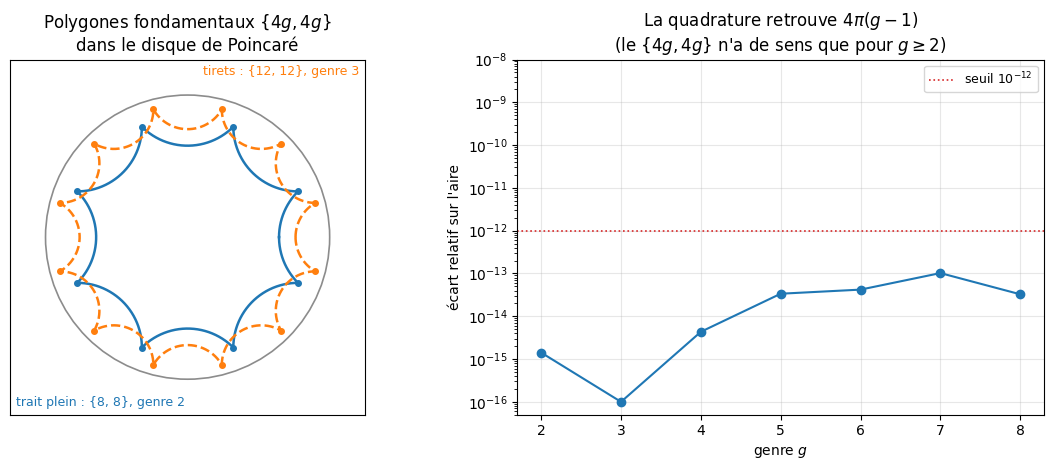

In [12]:
# Figure : à gauche, deux polygones fondamentaux du disque (genres 2 et 3) ;
# à droite, l'écart relatif entre l'aire intégrée et 4 pi (g-1), qui mesure la
# seule quadrature.
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11.5, 4.8))

cercle = plt.Circle((0, 0), 1, fill=False, color='0.55', lw=1.2)
gauche.add_patch(cercle)
for genre, couleur, style in ((2, 'tab:blue', '-'), (3, 'tab:orange', '--')):
    n, r_sommet, centre = polygone_regulier(genre)
    phi = np.linspace(0, 2*np.pi, 4001)
    delta = (phi + np.pi/n) % (2*np.pi/n) - np.pi/n
    rayon = centre*np.cos(delta) - np.sqrt(centre**2*np.cos(delta)**2 - 1)
    gauche.plot(rayon*np.cos(phi), rayon*np.sin(phi), style, color=couleur, lw=1.8)
    angles = np.pi/n + 2*np.pi*np.arange(n)/n
    gauche.plot(r_sommet*np.cos(angles), r_sommet*np.sin(angles), 'o', color=couleur, ms=4)
gauche.set_aspect('equal')
gauche.set_xlim(-1.25, 1.25)
gauche.set_ylim(-1.25, 1.25)
gauche.set_title('Polygones fondamentaux $\\{4g, 4g\\}$\ndans le disque de Poincaré')
# Étiquettes en direct, dans deux coins du cadre élargi : toute la bande de
# texte reste à distance supérieure à 1,1 de l'origine, donc hors du cercle
# unité. Une légende classique en coin recouvrirait les polygones.
gauche.text(-1.21, -1.21, 'trait plein : {8, 8}, genre 2', color='tab:blue',
            fontsize=9, va='bottom')
gauche.text(1.21, 1.21, 'tirets : {12, 12}, genre 3', color='tab:orange',
            fontsize=9, ha='right', va='top')
gauche.set_xticks([])
gauche.set_yticks([])

# L'écart peut être exactement nul (genre 3) : un zéro n'a pas de logarithme,
# on borne donc le tracé par un plancher.
plancher = 1e-16
genres = np.array([2, 3, 4, 5, 6, 7, 8])
ecarts = []
for genre in genres:
    r_sommet, aire, erreur = aire_polygone(genre)
    ecarts.append(abs(aire - 4*np.pi*(genre - 1))/(4*np.pi*(genre - 1)))
print("écarts relatifs de l'aire, g = 2..8 :", ['{:.1e}'.format(e) for e in ecarts])
droite.semilogy(genres, np.maximum(ecarts, plancher), 'o-', color='tab:blue')
droite.axhline(1e-12, color='tab:red', ls=':', lw=1.2, label='seuil $10^{-12}$')
droite.set_xlabel('genre $g$')
droite.set_ylabel('écart relatif sur l\'aire')
droite.set_ylim(plancher/2, 1e-8)
droite.set_title('La quadrature retrouve $4\\pi(g-1)$\n(le $\\{4g,4g\\}$ n\'a de sens que pour $g \\geq 2$)')
droite.set_xticks(genres)
droite.grid(alpha=0.3)
droite.legend(loc='upper right', fontsize=9)

fig.tight_layout()
plt.show()

**Lecture du résultat.** À gauche, l'octogone $\{8,8\}$, en trait plein, et le dodécagone $\{12,12\}$, en tirets, ont le même centre et un point à chaque sommet. Les sommets sont aux distances $0{,}841$ ($g = 2$) et $0{,}931$ ($g = 3$) du centre : ce sont les valeurs de la colonne « rayon » du tableau. Les deux polygones ne sont pas emboîtés : les sommets de l'octogone passent au-delà des côtés du dodécagone, et ceux du dodécagone au-delà des côtés de l'octogone. Ce sont des polygones réguliers d'angle intérieur $\pi/(2g)$ : $4g$ d'entre eux remplissent exactement $2\pi$ autour d'un sommet, et le recollement de leurs côtés donne la surface $\Sigma_g$. Leurs côtés sont des arcs géodésiques : dans le disque de Poincaré, un tel arc est incurvé vers le centre, et son milieu est plus proche du centre que ne le serait celui de la corde. À droite, l'écart relatif de la quadrature reste sous $10^{-12}$ pour tous les genres de 2 à 8 : l'aire intégrée vaut $4\pi(g-1)$ à $10^{-12}$ près, et la classe $4\pi^2\chi$ avec elle.

## 9. Le contre-témoin : la composante de Reeb

Un invariant n'est intéressant que s'il distingue. Le feuilletage de Reeb du tore solide est le contre-exemple classique : ses feuilles sont des plans qui s'enroulent autour du cœur, et le bord est une feuille compacte. On le définit par

$$\omega_{\mathrm{Reeb}} = dz - h'(r)\,dr, \qquad h(r) = \frac{r}{1-r},$$

sur le tore solide $\{0 \le r < 1\} \times S^1_z \times S^1_\varphi$. La forme est **fermée** : $h'(r)\,dr = dh$, donc $d\omega = 0$, et $\eta = 0$ est une solution — la classe doit s'annuler. Mais une forme fermée est un cas trop favorable pour être une épreuve de robustesse : le carnet multiplie donc $\omega$ par $f = (1 - r)^2$, ce qui la rend non fermée sans changer son feuilletage, et vérifie que la classe ne bouge pas.

In [13]:
r = sp.Symbol('r', positive=True)
z = sp.Symbol('z', real=True)
phi_tore = sp.Symbol('varphi', real=True)
univers_tore = Manifold('Tore', 3)
carte_tore = Patch('Pt', univers_tore)
coord_tore = CoordSystem('solide', carte_tore, [r, z, phi_tore])
rr, zz, phh = coord_tore.coord_functions()
dr, dz, dphi = coord_tore.base_oneforms()
R, Z, Ph = coord_tore.base_vectors()
base_tore = (R, Z, Ph)

h = rr/(1 - rr)
omega_reeb = dz - R(h)*dr
print("h(r) = r/(1-r), h'(r) =", sp.simplify(R(h)))
print("omega_Reeb fermée (d omega = 0) :", est_nulle(d(omega_reeb), 2, base_tore))

# Changement d'échelle : f = (1-r)^2. La forme n'est plus fermée, mais reste
# intégrable, et son eta est exact.
echelle = (1 - rr)**2
omega_echelle = echelle*omega_reeb
d_echelle = d(omega_echelle)
print("d((1-r)^2 omega_Reeb)(d/dr, d/dz) =", evalue(d_echelle, R, Z))
eta_reeb = -(R(echelle)/echelle)*dr
print("eta = -(d f / f) dr, évalué sur d/dr :", evalue(eta_reeb, R))
print("d(omega_echelle) = omega_echelle ^ eta :",
      est_nulle(d_echelle - produit_ext(omega_echelle, eta_reeb), 2, base_tore))
print("eta + d(ln f) = 0 (eta exacte) :", est_nulle(eta_reeb + d(sp.log(echelle)), 1, base_tore))
print("eta ^ d(eta) = 0 :", est_nulle(produit_ext(eta_reeb, d(eta_reeb)), 3, base_tore))

h(r) = r/(1-r), h'(r) = (r - 1)**(-2)
omega_Reeb fermée (d omega = 0) : True
d((1-r)^2 omega_Reeb)(d/dr, d/dz) = 2*r - 2
eta = -(d f / f) dr, évalué sur d/dr : -2/(r - 1)
d(omega_echelle) = omega_echelle ^ eta : True
eta + d(ln f) = 0 (eta exacte) : True
eta ^ d(eta) = 0 : True


**Lecture du résultat.** $\omega_{\mathrm{Reeb}}$ est fermée : $d\omega = 0$, donc $\eta = 0$ convient et la classe est nulle. Après le changement d'échelle $f = (1 - r)^2$, la forme n'est plus fermée — $d\tilde\omega(\partial_r, \partial_z) = 2r - 2$ — mais son $\eta$ vaut $-2\,dr/(r - 1)$ et vérifie $\eta = -d(\ln f)$ : c'est une forme **exacte**. Une forme exacte est fermée, donc $d\eta = 0$ et $\eta \wedge d\eta = 0$. Le mécanisme est net : la classe de Godbillon–Vey mesure ce qui, dans la forme de connexion $\eta$, n'est **pas** une dérivée. Ici, $\eta$ est la dérivée de $-\ln f$ : il ne reste rien.

Le contraste avec la section 7 est total. Là, $\eta = -\sqrt{c}\,\alpha_1$ n'est pas fermée : $d\eta = -\sqrt{c}\,\gamma \wedge \alpha_2$, et la classe est, au signe près, la forme de volume de Liouville. Ici, tout est dérivée. Le tore solide est en outre une variété à bord, de troisième cohomologie nulle : la classe y serait nulle pour une raison topologique, et le calcul en montre le mécanisme.

Reste l'holonomie de la feuille compacte. Sur le tore de bord, la longitude est le cercle $z$. Un point intérieur, à la distance $r$ du cœur, qui suit sa feuille pendant un tour de longitude ( $z \mapsto z + 1$ ) revient à la distance $r_1$ telle que $h(r_1) = h(r) + 1$ : il s'est rapproché du bord. En mesurant la distance au bord, $s = 1 - r$, la fonction d'holonomie est $H(s) = 1 - r_1(1 - s)$, et le carnet en donne le développement.

In [14]:
u, u1 = sp.symbols('u u1', real=True)
r1 = sp.solve(sp.Eq(u1/(1 - u1), u/(1 - u) + 1), u1)[0]
print("r1(u) =", sp.simplify(r1))
s = sp.Symbol('s', positive=True)
holonomie = sp.simplify(1 - r1.subs(u, 1 - s))
print("H(s) = 1 - r1(1-s) =", holonomie)
print("H(0) =", holonomie.subs(s, 0), "| H'(0) =", sp.diff(holonomie, s).subs(s, 0))
print("développement :", sp.series(holonomie, s, 0, 5))

r1(u) = -1/(u - 2)
H(s) = 1 - r1(1-s) = s/(s + 1)
H(0) = 0 | H'(0) = 1
développement : s - s**2 + s**3 - s**4 + O(s**5)


**Lecture du résultat.** $H(s) = s/(1+s)$ : dérivée $1$ en $0$ — l'identité au premier ordre, la marque d'une holonomie **parabolique** — puis $H(s) = s - s^2 + s^3 - \cdots < s$ : les feuilles voisines sont attirées vers la feuille compacte, au second ordre seulement. Le développement est une série entière, sans terme exponentiel : rien à voir avec les taux $\pm\sqrt{c}$ du flot géodésique. Sur cet exemple, la classe nulle va de pair avec une holonomie parabolique — le retour des feuilles voisines ne fait ni contraction ni dilatation au premier ordre.

## 10. Ce que le carnet ne refait pas

Deux résultats de la théorie restent en dehors de ce carnet, et rien ici ne s'en sert :

- les **feuilletages non cobordants de $S^3$** étudiés par Thurston en 1972 (W. P. Thurston, *Noncobordant foliations of $S^3$*, Bulletin of the American Mathematical Society **78**(4), 1972, p. 511–514) : ce carnet calcule la classe sur deux exemples, il n'aborde pas la question des valeurs qu'elle prend sur une variété donnée ;
- les **structures de Haefliger**, où la classe de Godbillon–Vey se lit comme une classe caractéristique sur l'espace classifiant des feuilletages : hors du périmètre de ce carnet.

Ce que le carnet établit est autonome. Sur un exemple calculé de bout en bout — le feuilletage instable faible d'une surface hyperbolique — la classe vaut $4\pi^2\chi$, non nulle dès que $g \ge 2$. Sur un autre — la composante de Reeb — elle vaut $0$, et le calcul en donne le mécanisme : une forme $\eta$ exacte.

## À retenir

- **Un feuilletage de codimension 1 se définit par une forme**, et son intégrabilité se teste par $\omega \wedge d\omega = 0$ — un calcul, pas une figure.
- **$d\omega = \omega \wedge \eta$ est un système linéaire** : ses rangs décident. Rang 2 contre rang 3, aucune solution : pas de feuilletage. Rangs égaux : $\eta$ existe, défini à un multiple de $\omega$ près.
- **Intégrabilité et invariance par le flot sont la même équation** : pour un plan qui contient $E_1$, $c\lambda^2 - 1 = 0$ est à la fois le zéro du tableau de Frobenius et celui du critère d'invariance.
- **$\eta \wedge d\eta$ est une classe de de Rham** : changer $\omega$ d'échelle ou $\eta$ de jauge ne change que la différentielle exacte — vérifié avec des fonctions arbitraires.
- **Sur $T^1\Sigma_g$, la classe vaut $4\pi^2\chi(\Sigma_g)$** : le feuilletage instable faible du flot géodésique porte une classe égale à $-2\pi$ fois l'aire de la surface, et cette aire se recalcule par quadrature sur le polygone $\{4g,4g\}$.
- **La composante de Reeb est le contre-témoin** : $\eta$ exacte, holonomie parabolique, classe nulle.

## Vérifiez votre compréhension

Trois exercices, sur le modèle des calculs du carnet. Les fonctions définies plus haut (`evalue`, `produit_ext`, `est_nulle`, `equations_eta`) et les objets (`alpha1`, `alpha2`, `gamma`, `c`, `omega`, `eta`, `classe`, `base_vecteurs`) restent disponibles. Chaque cellule s'exécute sans complétion : elle imprime un message et rend `None`. Complétez le corps de la fonction, puis comparez avec les réponses repliées à la fin.

### Exercice 1 — La classe du feuilletage stable faible

Le carnet a calculé la classe du feuilletage **instable** faible, $\ker(\alpha_2 + \gamma/\sqrt{c})$. Calculez celle du feuilletage **stable** faible, $\ker(\alpha_2 - \gamma/\sqrt{c})$, dans la jauge $b = 0$. La fonction rend la 3-forme $\eta \wedge d\eta$ évaluée sur les champs de coordonnées. Obtient-on la même valeur, ou son opposée ?

In [15]:
def classe_feuilletage_stable():
    # Écrit la forme du feuilletage stable faible, omega_s = alpha2 - gamma/sqrt(c),
    # et son eta dans la jauge b = 0 (se reporter au solveur de la section 6).
    # Indice : avec eta_s = a alpha1, l'équation de structure d(omega_s) = omega_s ^ eta_s
    # fixe le signe de a ; la classe est produit_ext(eta_s, d(eta_s)), à évaluer
    # avec evalue( . , *base_vecteurs).
    # TODO étudiant : retourner la valeur de eta_s ^ d(eta_s) sur (d/dx, d/dy, d/dtheta).
    print("Exercice à compléter : classe du feuilletage stable faible.")
    return None


print("appel sans complétion ->", classe_feuilletage_stable())

Exercice à compléter : classe du feuilletage stable faible.
appel sans complétion -> None


### Exercice 2 — Une jauge d'échelle concrète

La section 7 a vérifié l'identité de jauge avec $\varphi$ arbitraire. Faites-le pour $\varphi = \ln y$, c'est-à-dire pour $\omega \mapsto y\,\omega$ : la nouvelle forme de connexion est $\eta_y = \eta - d(\ln y)$. La fonction rend un triplet : l'équation de structure $d(y\omega) = y\,\omega \wedge \eta_y$ est-elle vérifiée, la classe est-elle inchangée à une différentielle exacte près, et que vaut $\eta_y(\partial_y)$ ?

In [16]:
def jauge_echelle_y():
    # Reprend omega et eta de la section 7, remplace omega par y*omega et eta par
    # eta_y = eta - d(log(y)).
    # Indice : est_nulle( . , degre, base_vecteurs) teste une identité de formes ;
    # pour la classe, comparer produit_ext(eta_y, d(eta_y)) - classe à -d(log(y)*d(eta)).
    # TODO étudiant : retourner (équation de structure, classe inchangée, eta_y sur d/dy).
    print("Exercice à compléter : jauge d'échelle omega -> y omega.")
    return None


print("appel sans complétion ->", jauge_echelle_y())

Exercice à compléter : jauge d'échelle omega -> y omega.
appel sans complétion -> None


### Exercice 3 — L'holonomie d'un autre profil de Reeb

Reprenez le calcul d'holonomie avec $h(r) = r^2/(1 - r)$. Un tour de longitude envoie $u$ sur $r_1$, solution de $r_1^2/(1 - r_1) = u^2/(1 - u) + 1$. La fonction rend, pour $s = 10^{-2}$, $10^{-3}$ et $10^{-4}$, les valeurs de $H(s)/s$, où $H(s) = 1 - r_1(1 - s)$. L'holonomie est-elle encore parabolique ?

In [17]:
def holonomie_profil_carre():
    # Même calcul que ci-dessus, avec h(u) = u**2/(1 - u) : résoudre
    # r1**2/(1 - r1) = u**2/(1 - u) + 1 en r1 (prendre la racine dans ]0, 1[),
    # poser H(s) = 1 - r1(1 - s), puis évaluer H(s)/s pour s dans (1e-2, 1e-3, 1e-4).
    # Indice : sp.solve rend deux racines ; la bonne est celle qui reste dans
    # ]0, 1[ quand u y est (l'autre est négative).
    # TODO étudiant : retourner la liste des trois rapports H(s)/s.
    print("Exercice à compléter : holonomie du profil h(r) = r^2/(1 - r).")
    return None


print("appel sans complétion ->", holonomie_profil_carre())

Exercice à compléter : holonomie du profil h(r) = r^2/(1 - r).
appel sans complétion -> None


<details>
<summary>Éléments de réponse</summary>

**Exercice 1.** La même valeur, pas son opposée : $\eta_s = \sqrt{c}\,\alpha_1$ (le signe de $a$ est l'inverse de celui du feuilletage instable) vérifie l'équation de structure, et $\eta_s \wedge d\eta_s$ vaut $-1/y^2$ sur les champs de coordonnées. Le signe moins d'un côté, plus de l'autre, disparaît dans le produit : les deux feuilletages faibles portent la même classe.

**Exercice 2.** Les deux identités sont vérifiées, et $\eta_y(\partial_y) = -(\sin\theta + 1)/y$. La forme de connexion a changé ; sa classe non : la différence entre les deux classes est $-d(\ln y\; d\eta)$, une différentielle exacte.

**Exercice 3.** $H(s)/s$ vaut $0{,}99009804$, $0{,}99900100$ et $0{,}99990001$ : il tend vers $1$ en $0$, et l'écart $H(s) - s$ est en $-s^2$. L'holonomie est encore parabolique, avec le même terme quadratique que pour le profil $r/(1 - r)$.

</details>

## Pour aller plus loin

- **Les quatre feuilletages intégrables.** Le carnet a calculé la classe du feuilletage instable faible $\ker(\alpha_2 + \gamma/\sqrt{c})$ et celle de $\ker(\alpha_1 + \gamma/\sqrt{c})$, image du feuilletage stable faible par le quart de tour dans la fibre ; l'exercice 1 traite le feuilletage stable faible $\ker(\alpha_2 - \gamma/\sqrt{c})$ lui-même. Il en reste un quatrième, $\ker(\alpha_1 - \gamma/\sqrt{c})$, l'image du feuilletage instable faible : sa classe se calcule de la même manière.
- **Le flot géodésique en dynamique.** Les taux $\pm\sqrt{c}$ sont les exposants de Liapounov du flot géodésique d'une surface de courbure $-c$ : c'est un pont naturel vers la théorie ergodique.
- **La formule générale.** Sur une variété de dimension 3, $\mathrm{GV}$ vit dans $H^3$ ; pour un feuilletage de codimension $q$ d'une variété de dimension $n$, la classe vit dans $H^{2q+1}$.
- **Les autres carnets de la série.** KNOTS-04 calcule le volume hyperbolique d'un complémentaire de nœud par ses tétraèdres idéaux, KNOTS-05 étudie la dynamique des tresses, KNOTS-06 les empilements de cercles : trois autres calculs de la même série.

## Références

- C. Godbillon, J. Vey, *Un invariant des feuilletages de codimension 1*, Comptes Rendus de l'Académie des Sciences de Paris, Série A-B **273**, 1971, p. A92–A95 — repère bibliographique.
- W. P. Thurston, *Noncobordant foliations of $S^3$*, Bulletin of the American Mathematical Society **78**(4), 1972, p. 511–514, doi `10.1090/S0002-9904-1972-12975-6` — repère bibliographique.
- SymPy Development Team, *SymPy 1.14 — `sympy.diffgeom`*, documentation du module, installée avec la bibliothèque : formes différentielles, `CoordSystem`, `Differential`, `WedgeProduct`. C'est l'organe de calcul du carnet.

**État de lecture.** Les deux publications mathématiques ne sont ni archivées dans le gisement partagé ni lues pour écrire ce carnet : ce sont des repères, sans attribution de résultat lu directement. La définition de la classe, ses identités de jauge et sa valeur sur $T^1\Sigma_g$ sont établies par les calculs du carnet. Les fonctions de `sympy.diffgeom` citées sont celles de la version exécutée.